       CNN FOR TOMATO LEAF DISEASE CLASSIFICATION

Experiment Configuration
---------------------------------------------------------------------------
Image Size          : 128 x 128
Batch Size          : 64
Epochs              : 8
Learning Rate       : 0.001
Number of Classes   : 10
Training Samples    : 7000
Validation Samples  : 1500
Testing Samples     : 1500

LOADING TOMATO LEAF DATASET

Downloading/loading dataset from Hugging Face...


README.md:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11000 [00:00<?, ? examples/s]


Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 11000
    })
})

Total images available:
11000

DATASET INFORMATION
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Bacterial Spot', 'Early Blight', 'Healthy', 'Late Blight', 'Leaf Mold', 'Septoria Leaf Spot', 'Spider Mites Two-spotted Spider Mite', 'Target Spot', 'Tomato Mosaic Virus', 'Tomato Yellow Leaf Curl Virus'])}

Classes found:
---------------------------------------------------------------------------
0: Bacterial Spot
1: Early Blight
2: Healthy
3: Late Blight
4: Leaf Mold
5: Septoria Leaf Spot
6: Spider Mites Two-spotted Spider Mite
7: Target Spot
8: Tomato Mosaic Virus
9: Tomato Yellow Leaf Curl Virus

Number of classes detected: 10

CHECKING CLASS DISTRIBUTION
Bacterial Spot                      : 1100 images
Early Blight                        : 1100 images
Healthy                             : 1100 images
Late Blight               

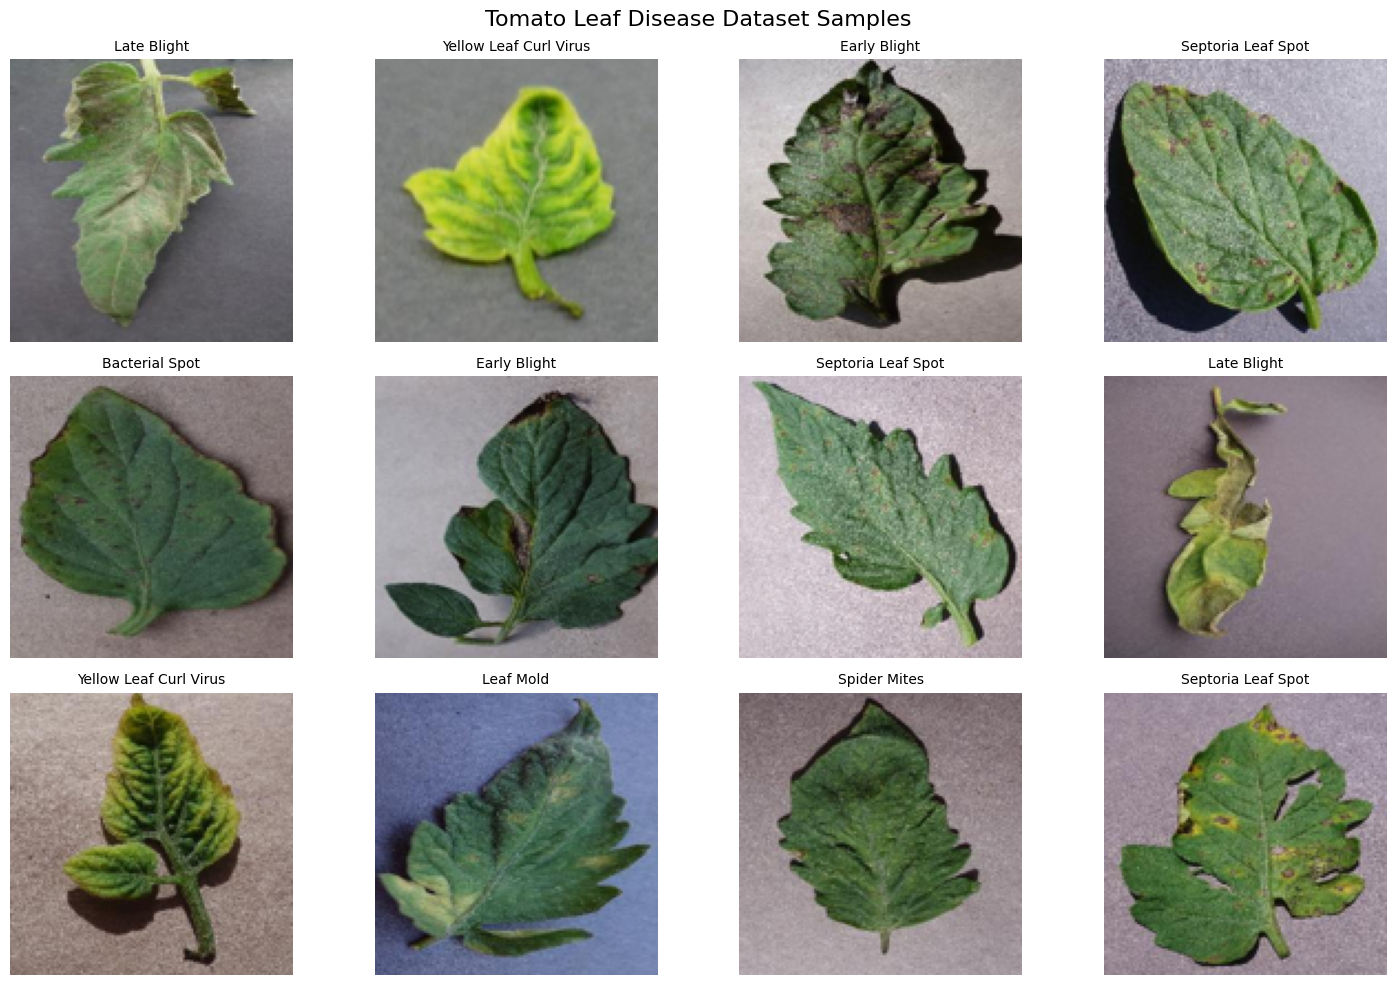

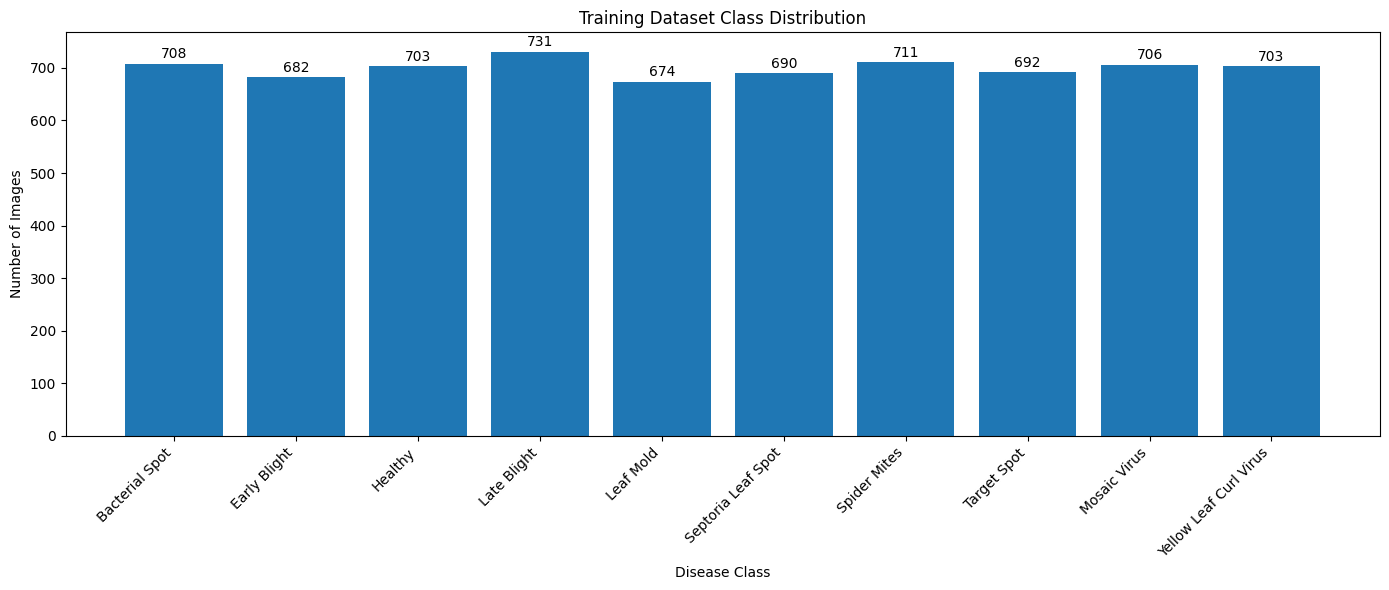


BUILDING CNN MODEL

Model created successfully.
Total parameters: 3,305,930

TRAINING CNN
Epoch 1/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 11s 48ms/step - accuracy: 0.4244 - loss: 1.6309 - val_accuracy: 0.6893 - val_loss: 0.9335
Epoch 2/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.6643 - loss: 0.9866 - val_accuracy: 0.7707 - val_loss: 0.6577
Epoch 3/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.7447 - loss: 0.7550 - val_accuracy: 0.7720 - val_loss: 0.6113
Epoch 4/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.7797 - loss: 0.6456 - val_accuracy: 0.8180 - val_loss: 0.5119
Epoch 5/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.7991 - loss: 0.5764 - val_accuracy: 0.8580 - val_loss: 0.3881
Epoch 6/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.8339 - loss: 0.4875 - val_accuracy: 0.8807 - val_loss: 0.3279
Epoch 7/8
110/110 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.8474 - loss: 0.4337 - val_accuracy: 0.8860 - val_loss: 0.3441
Epoch 8/8
11

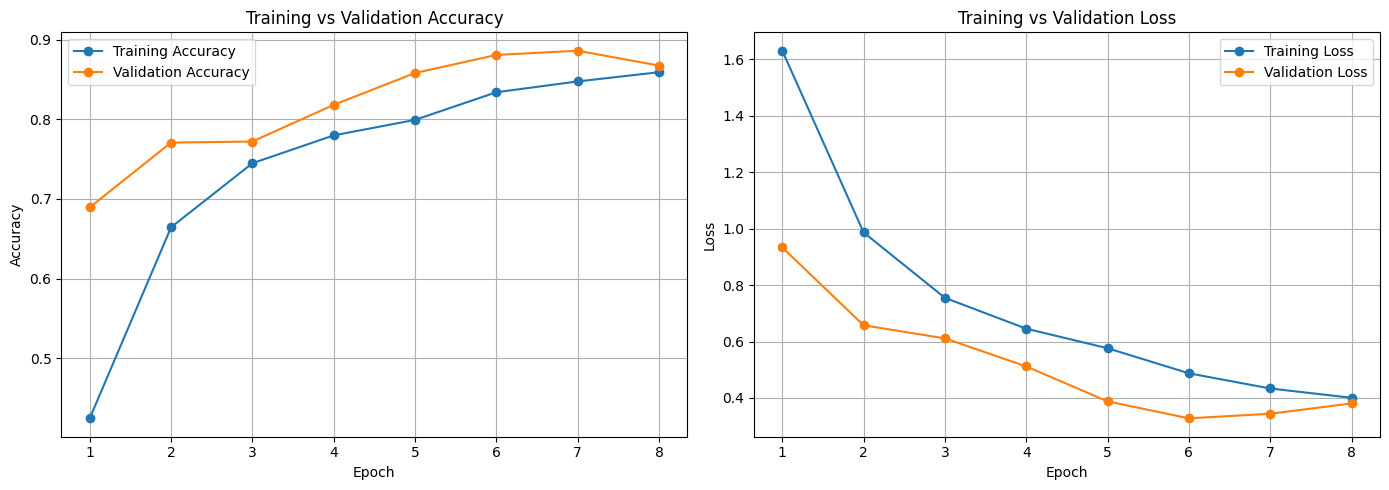


GENERATING PREDICTIONS
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step

Overall Metrics
---------------------------------------------------------------------------
Accuracy  : 0.8593
Precision : 0.8668
Recall    : 0.8593
F1 Score  : 0.8603


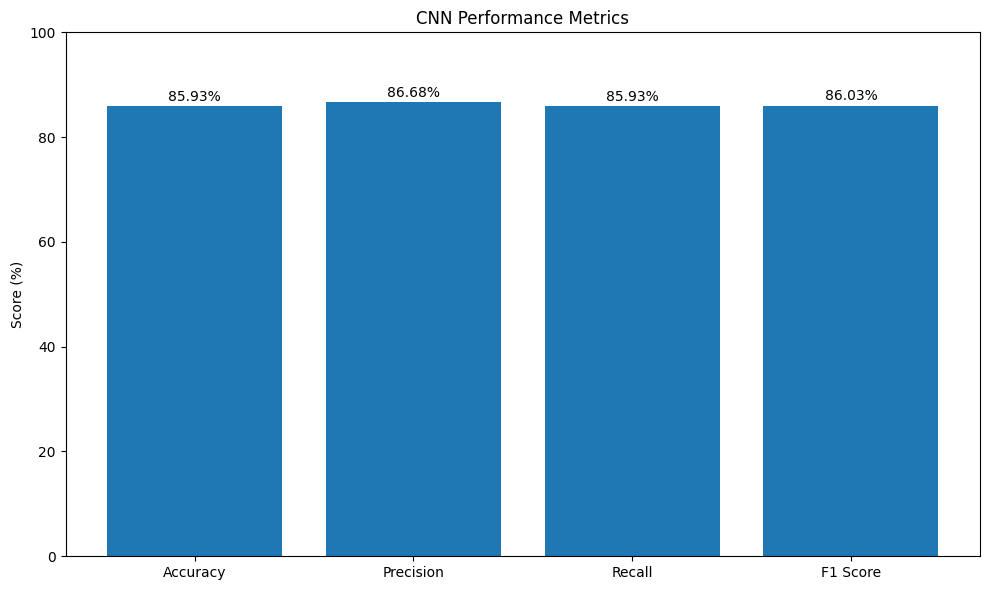


CONFUSION MATRIX


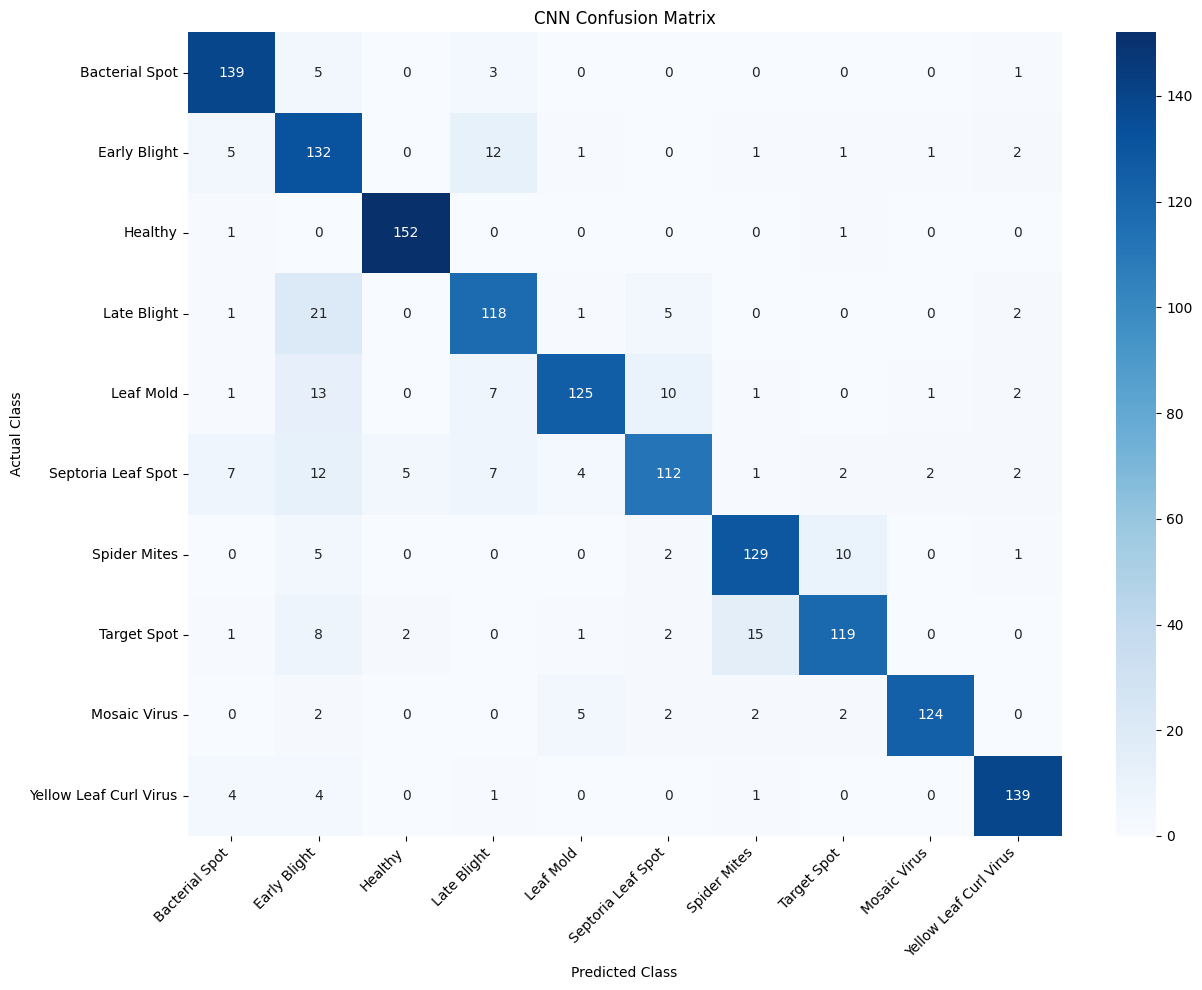


CLASSIFICATION REPORT
                        precision    recall  f1-score   support

        Bacterial Spot       0.87      0.94      0.91       148
          Early Blight       0.65      0.85      0.74       155
               Healthy       0.96      0.99      0.97       154
           Late Blight       0.80      0.80      0.80       148
             Leaf Mold       0.91      0.78      0.84       160
    Septoria Leaf Spot       0.84      0.73      0.78       154
          Spider Mites       0.86      0.88      0.87       147
           Target Spot       0.88      0.80      0.84       148
          Mosaic Virus       0.97      0.91      0.94       137
Yellow Leaf Curl Virus       0.93      0.93      0.93       149

              accuracy                           0.86      1500
             macro avg       0.87      0.86      0.86      1500
          weighted avg       0.87      0.86      0.86      1500


PER-CLASS ACCURACY
Bacterial Spot                      : 93.92%
Early Blight 

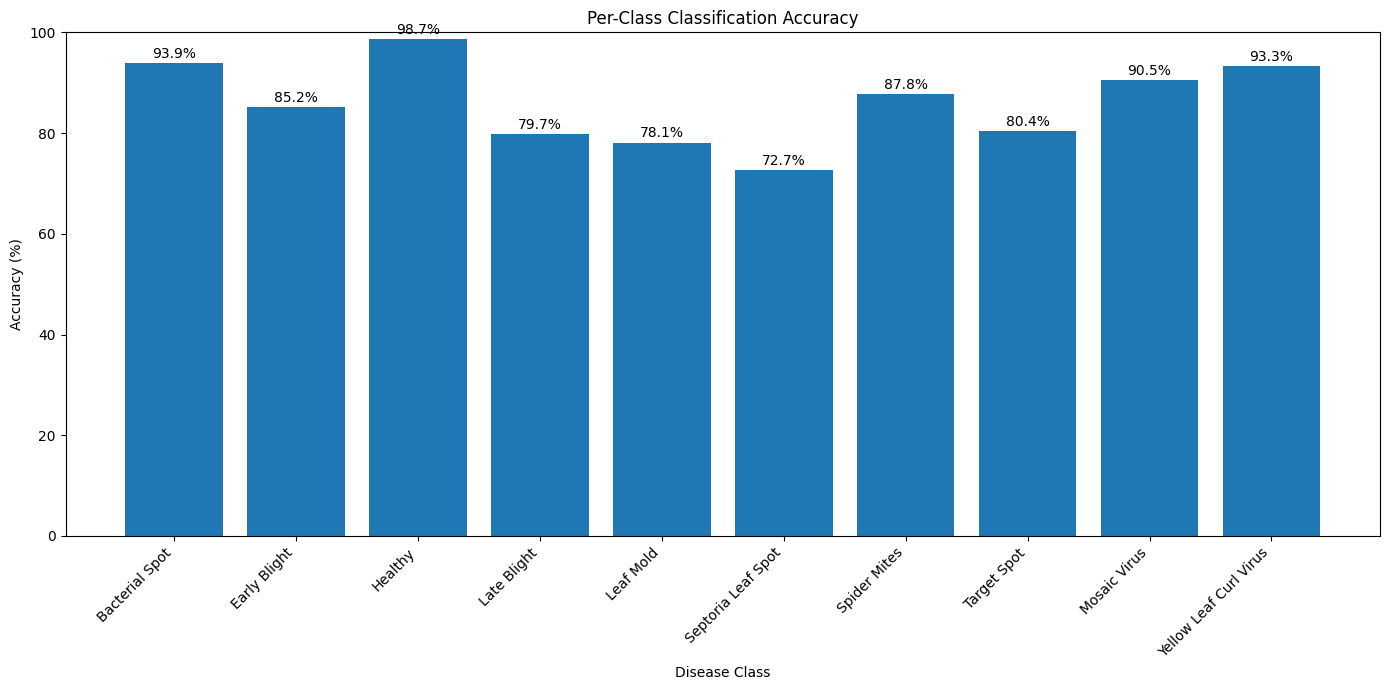


SAMPLE PREDICTIONS


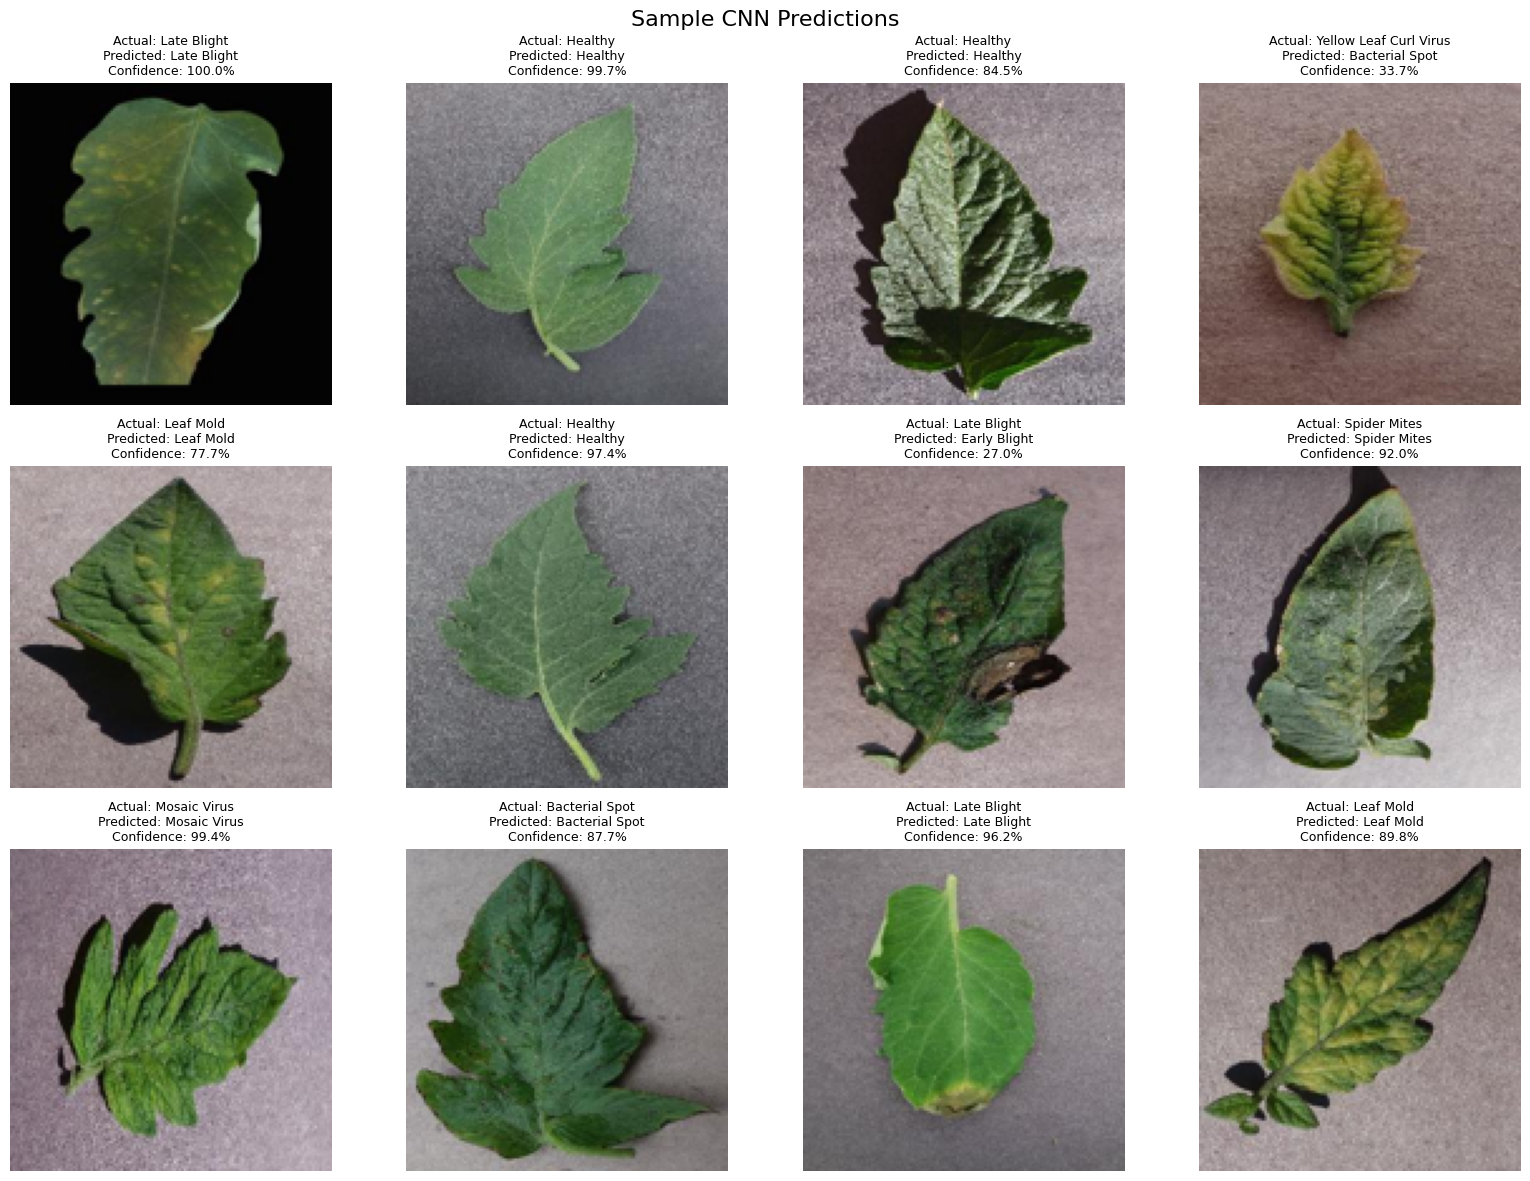


Correct predictions   : 1289
Incorrect predictions : 211

INCORRECT PREDICTIONS


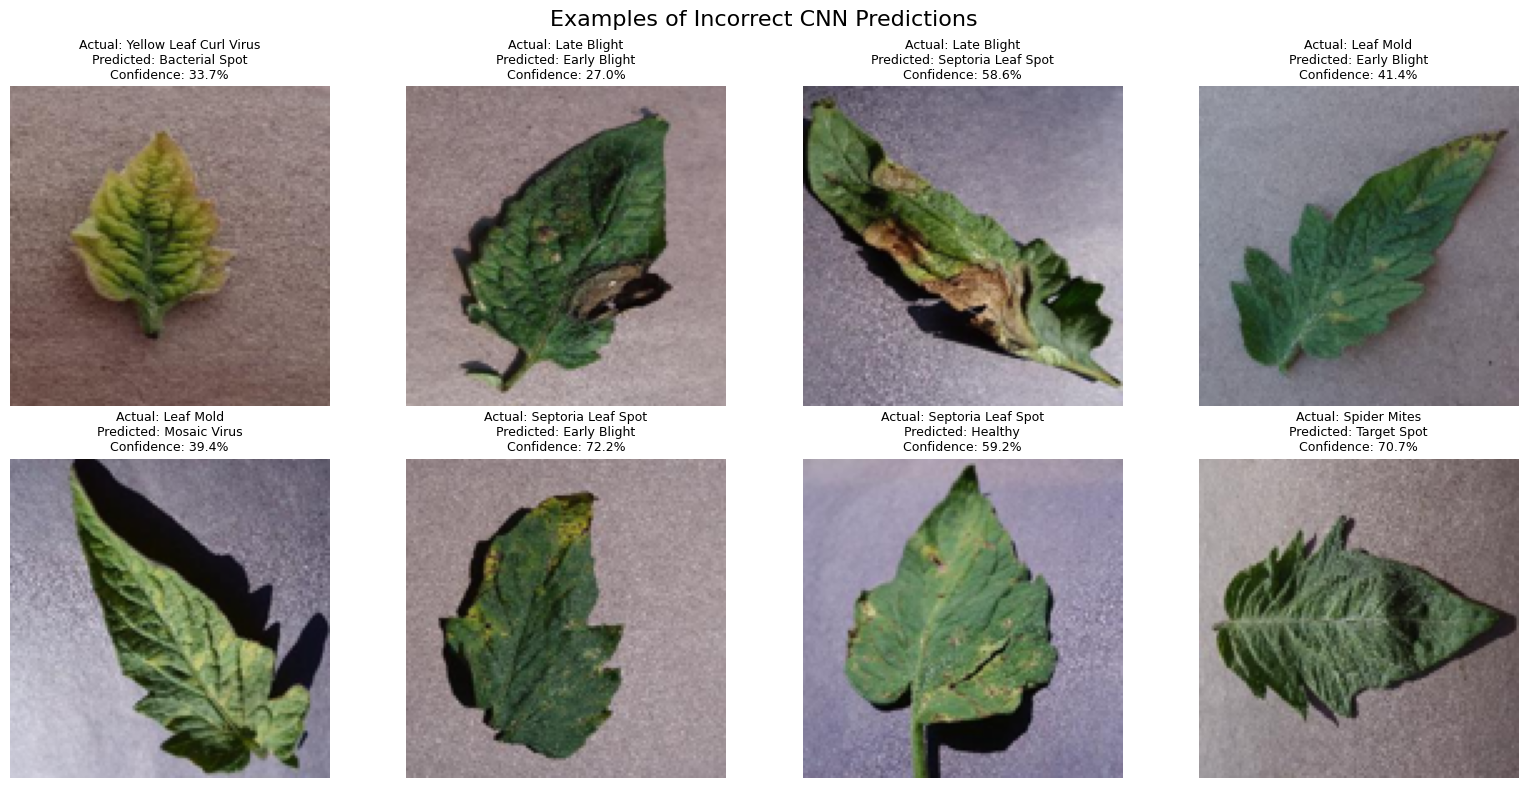


FINAL RESULTS
Training Accuracy   : 85.90%
Validation Accuracy : 86.73%
Test Accuracy       : 85.93%
Precision           : 86.68%
Recall              : 85.93%
F1 Score            : 86.03%
Training Time       : 46.00 seconds
Total Parameters    : 3,305,930
Training Samples    : 7000
Validation Samples  : 1500
Testing Samples     : 1500
CNN EXPERIMENT COMPLETED


In [1]:
# ================================================================
# CNN FOR TOMATO LEAF DISEASE CLASSIFICATION
# ================================================================
# Install required packages
!pip install -q datasets tensorflow matplotlib seaborn scikit-learn
import os
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from datasets import load_dataset
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
# ================================================================
# TITLE
# ================================================================
print("=" * 75)
print("       CNN FOR TOMATO LEAF DISEASE CLASSIFICATION")
print("=" * 75)
# ================================================================
# EXPERIMENT CONFIGURATION
# ================================================================
IMAGE_SIZE = 128
BATCH_SIZE = 64
EPOCHS = 8
LEARNING_RATE = 0.001
NUM_CLASSES = 10
TRAIN_SAMPLES = 7000
VALIDATION_SAMPLES = 1500
TEST_SAMPLES = 1500
TOTAL_SAMPLES = (
    TRAIN_SAMPLES +
    VALIDATION_SAMPLES +
    TEST_SAMPLES
)
SEED = 42
print("\nExperiment Configuration")
print("-" * 75)
print(f"Image Size          : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Batch Size          : {BATCH_SIZE}")
print(f"Epochs              : {EPOCHS}")
print(f"Learning Rate       : {LEARNING_RATE}")
print(f"Number of Classes   : {NUM_CLASSES}")
print(f"Training Samples    : {TRAIN_SAMPLES}")
print(f"Validation Samples  : {VALIDATION_SAMPLES}")
print(f"Testing Samples     : {TEST_SAMPLES}")
# ================================================================
# REPRODUCIBILITY
# ================================================================
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except:
    pass
# ================================================================
# LOAD DATASET FROM HUGGING FACE
# ================================================================
print("\n" + "=" * 75)
print("LOADING TOMATO LEAF DATASET")
print("=" * 75)
print("\nDownloading/loading dataset from Hugging Face...")
dataset = load_dataset(
    "Project-AgML/tomato_leaf_disease"
)
print("\nDataset loaded successfully!")
print(dataset)
# ================================================================
# GET DATASET SPLIT
# ================================================================
full_dataset = dataset["train"]
print("\nTotal images available:")
print(len(full_dataset))
# ================================================================
# CHECK DATASET FEATURES
# ================================================================
print("\n" + "=" * 75)
print("DATASET INFORMATION")
print("=" * 75)
print(full_dataset.features)
# ================================================================
# GET CLASS INFORMATION
# ================================================================
label_feature = full_dataset.features["label"]
CLASS_NAMES = label_feature.names
NUM_CLASSES = len(CLASS_NAMES)
print("\nClasses found:")
print("-" * 75)
for i, class_name in enumerate(CLASS_NAMES):
    print(f"{i}: {class_name}")
print(f"\nNumber of classes detected: {NUM_CLASSES}")
# ================================================================
# DISPLAY NAMES
# ================================================================
DISPLAY_NAMES = [
    "Bacterial Spot",
    "Early Blight",
    "Healthy",
    "Late Blight",
    "Leaf Mold",
    "Septoria Leaf Spot",
    "Spider Mites",
    "Target Spot",
    "Mosaic Virus",
    "Yellow Leaf Curl Virus"
]
# Make sure display names match dataset classes
if len(DISPLAY_NAMES) != NUM_CLASSES:
    DISPLAY_NAMES = CLASS_NAMES
# ================================================================
# CHECK CLASS DISTRIBUTION
# ================================================================
print("\n" + "=" * 75)
print("CHECKING CLASS DISTRIBUTION")
print("=" * 75)
label_values = np.array(
    full_dataset["label"]
)
for i in range(NUM_CLASSES):
    count = np.sum(
        label_values == i
    )
    print(
        f"{DISPLAY_NAMES[i]:<35} : {count} images"
    )
# ================================================================
# SHUFFLE DATASET
# ================================================================
print("\n" + "=" * 75)
print("PREPARING DATASET")
print("=" * 75)
full_dataset = full_dataset.shuffle(
    seed=SEED
)
# ================================================================
# SELECT REQUIRED NUMBER OF IMAGES
# ================================================================
if len(full_dataset) < TOTAL_SAMPLES:
    raise ValueError(
        f"Dataset contains only {len(full_dataset)} images, "
        f"but {TOTAL_SAMPLES} are required."
    )
selected_dataset = full_dataset.select(
    range(TOTAL_SAMPLES)
)
print(
    f"\nSelected {len(selected_dataset)} images "
    f"for the experiment."
)
# ================================================================
# CREATE TRAIN / VALIDATION / TEST SPLIT
# ================================================================
print("\n" + "=" * 75)
print("CREATING TRAIN / VALIDATION / TEST SPLIT")
print("=" * 75)
train_dataset = selected_dataset.select(
    range(
        0,
        TRAIN_SAMPLES
    )
)
validation_dataset = selected_dataset.select(
    range(
        TRAIN_SAMPLES,
        TRAIN_SAMPLES + VALIDATION_SAMPLES
    )
)
test_dataset = selected_dataset.select(
    range(
        TRAIN_SAMPLES + VALIDATION_SAMPLES,
        TOTAL_SAMPLES
    )
)
print(
    f"Training samples   : {len(train_dataset)}"
)
print(
    f"Validation samples : {len(validation_dataset)}"
)
print(
    f"Testing samples    : {len(test_dataset)}"
)
# ================================================================
# CONVERT HUGGING FACE IMAGE TO NUMPY
# ================================================================
def prepare_images(dataset_split):
    images = []
    labels = []
    for item in dataset_split:
        image = item["image"]
        # Convert to RGB
        image = image.convert("RGB")
        # Resize
        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )
        # Convert to NumPy
        image = np.array(
            image,
            dtype=np.float32
        )
        # Normalize pixels
        image = image / 255.0
        images.append(image)
        labels.append(
            item["label"]
        )
    images = np.array(
        images,
        dtype=np.float32
    )
    labels = np.array(
        labels,
        dtype=np.int32
    )
    return images, labels
# ================================================================
# PREPARE TRAINING DATA
# ================================================================
print("\n" + "=" * 75)
print("PREPARING TRAINING DATA")
print("=" * 75)
start_prepare = time.time()
X_train, y_train = prepare_images(
    train_dataset
)
print(
    f"Training data shape: "
    f"{X_train.shape}"
)
# ================================================================
# PREPARE VALIDATION DATA
# ================================================================
print("\nPreparing validation data...")
X_validation, y_validation = prepare_images(
    validation_dataset
)
print(
    f"Validation data shape: "
    f"{X_validation.shape}"
)
# ================================================================
# PREPARE TEST DATA
# ================================================================
print("\nPreparing test data...")
X_test, y_test = prepare_images(
    test_dataset
)
print(
    f"Test data shape: "
    f"{X_test.shape}"
)
preparation_time = (
    time.time() - start_prepare
)
print(
    f"\nData preparation time: "
    f"{preparation_time:.2f} seconds"
)
# ================================================================
# CREATE TF.DATA DATASETS
# ================================================================
train_tf_dataset = tf.data.Dataset.from_tensor_slices(
    (
        X_train,
        y_train
    )
)
validation_tf_dataset = tf.data.Dataset.from_tensor_slices(
    (
        X_validation,
        y_validation
    )
)
test_tf_dataset = tf.data.Dataset.from_tensor_slices(
    (
        X_test,
        y_test
    )
)
# ================================================================
# SHUFFLE AND BATCH
# ================================================================
train_tf_dataset = (
    train_tf_dataset
    .shuffle(
        buffer_size=len(X_train),
        seed=SEED,
        reshuffle_each_iteration=False
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
validation_tf_dataset = (
    validation_tf_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
test_tf_dataset = (
    test_tf_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
# ================================================================
# VISUALIZE SAMPLE IMAGES
# ================================================================
print("\n" + "=" * 75)
print("DISPLAYING SAMPLE IMAGES")
print("=" * 75)
plt.figure(
    figsize=(15, 10)
)
for i in range(12):
    plt.subplot(
        3,
        4,
        i + 1
    )
    plt.imshow(
        X_train[i]
    )
    plt.title(
        DISPLAY_NAMES[
            y_train[i]
        ],
        fontsize=10
    )
    plt.axis("off")
plt.suptitle(
    "Tomato Leaf Disease Dataset Samples",
    fontsize=16
)
plt.tight_layout()
plt.show()
# ================================================================
# CLASS DISTRIBUTION GRAPH
# ================================================================
class_counts = []
for i in range(NUM_CLASSES):
    class_counts.append(
        np.sum(
            y_train == i
        )
    )
plt.figure(
    figsize=(14, 6)
)
bars = plt.bar(
    DISPLAY_NAMES,
    class_counts
)
plt.title(
    "Training Dataset Class Distribution"
)
plt.xlabel(
    "Disease Class"
)
plt.ylabel(
    "Number of Images"
)
plt.xticks(
    rotation=45,
    ha="right"
)
for bar, value in zip(
    bars,
    class_counts
):
    plt.text(
        bar.get_x() +
        bar.get_width() / 2,
        bar.get_height() + 10,
        str(value),
        ha="center"
    )
plt.tight_layout()
plt.show()
# ================================================================
# BUILD CNN MODEL
# ================================================================
print("\n" + "=" * 75)
print("BUILDING CNN MODEL")
print("=" * 75)
model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(
            IMAGE_SIZE,
            IMAGE_SIZE,
            3
        )
    ),
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),
    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),
    tf.keras.layers.Dropout(
        0.5
    ),
    tf.keras.layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])
# ================================================================
# COMPILE MODEL
# ================================================================
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy"
    ]
)
print("\nModel created successfully.")
print(
    f"Total parameters: "
    f"{model.count_params():,}"
)
# ================================================================
# TRAIN MODEL
# ================================================================
print("\n" + "=" * 75)
print("TRAINING CNN")
print("=" * 75)
start_time = time.time()
history = model.fit(
    train_tf_dataset,
    validation_data=validation_tf_dataset,
    epochs=EPOCHS,
    verbose=1
)
training_time = (
    time.time() -
    start_time
)
print("\nTraining completed!")
print(
    f"Training Time: "
    f"{training_time:.2f} seconds"
)
# ================================================================
# FINAL TEST EVALUATION
# ================================================================
print("\n" + "=" * 75)
print("FINAL TEST EVALUATION")
print("=" * 75)
test_loss, test_accuracy = model.evaluate(
    test_tf_dataset,
    verbose=0
)
print(
    f"\nTest Loss     : "
    f"{test_loss:.4f}"
)
print(
    f"Test Accuracy : "
    f"{test_accuracy:.4f}"
)
print(
    f"Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)
# ================================================================
# TRAINING AND VALIDATION GRAPHS
# ================================================================
print("\n" + "=" * 75)
print("TRAINING PERFORMANCE")
print("=" * 75)
epochs_range = range(
    1,
    EPOCHS + 1
)
plt.figure(
    figsize=(14, 5)
)
# ------------------------------------------------
# ACCURACY
# ------------------------------------------------
plt.subplot(
    1,
    2,
    1
)
plt.plot(
    epochs_range,
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    epochs_range,
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)
plt.title(
    "Training vs Validation Accuracy"
)
plt.xlabel(
    "Epoch"
)
plt.ylabel(
    "Accuracy"
)
plt.xticks(
    epochs_range
)
plt.legend()
plt.grid(True)
# ------------------------------------------------
# LOSS
# ------------------------------------------------
plt.subplot(
    1,
    2,
    2
)
plt.plot(
    epochs_range,
    history.history["loss"],
    marker="o",
    label="Training Loss"
)
plt.plot(
    epochs_range,
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)
plt.title(
    "Training vs Validation Loss"
)
plt.xlabel(
    "Epoch"
)
plt.ylabel(
    "Loss"
)
plt.xticks(
    epochs_range
)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
# ================================================================
# GENERATE TEST PREDICTIONS
# ================================================================
print("\n" + "=" * 75)
print("GENERATING PREDICTIONS")
print("=" * 75)
prediction_probabilities = model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=1
)
y_pred = np.argmax(
    prediction_probabilities,
    axis=1
)
y_true = y_test
# ================================================================
# CLASSIFICATION METRICS
# ================================================================
accuracy = accuracy_score(
    y_true,
    y_pred
)
precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)
recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)
f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)
print("\nOverall Metrics")
print("-" * 75)
print(
    f"Accuracy  : "
    f"{accuracy:.4f}"
)
print(
    f"Precision : "
    f"{precision:.4f}"
)
print(
    f"Recall    : "
    f"{recall:.4f}"
)
print(
    f"F1 Score  : "
    f"{f1:.4f}"
)
# ================================================================
# METRIC COMPARISON GRAPH
# ================================================================
metrics_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]
metrics_values = [
    accuracy,
    precision,
    recall,
    f1
]
plt.figure(
    figsize=(10, 6)
)
bars = plt.bar(
    metrics_names,
    np.array(metrics_values) * 100
)
plt.title(
    "CNN Performance Metrics"
)
plt.ylabel(
    "Score (%)"
)
plt.ylim(
    0,
    100
)
for bar, value in zip(
    bars,
    metrics_values
):
    plt.text(
        bar.get_x() +
        bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value * 100:.2f}%",
        ha="center"
    )
plt.tight_layout()
plt.show()
# ================================================================
# CONFUSION MATRIX
# ================================================================
print("\n" + "=" * 75)
print("CONFUSION MATRIX")
print("=" * 75)
cm = confusion_matrix(
    y_true,
    y_pred
)
plt.figure(
    figsize=(13, 10)
)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=DISPLAY_NAMES,
    yticklabels=DISPLAY_NAMES
)
plt.title(
    "CNN Confusion Matrix"
)
plt.xlabel(
    "Predicted Class"
)
plt.ylabel(
    "Actual Class"
)
plt.xticks(
    rotation=45,
    ha="right"
)
plt.yticks(
    rotation=0
)
plt.tight_layout()
plt.show()
# ================================================================
# CLASSIFICATION REPORT
# ================================================================
print("\n" + "=" * 75)
print("CLASSIFICATION REPORT")
print("=" * 75)
print(
    classification_report(
        y_true,
        y_pred,
        target_names=DISPLAY_NAMES,
        zero_division=0
    )
)
# ================================================================
# PER-CLASS ACCURACY
# ================================================================
print("\n" + "=" * 75)
print("PER-CLASS ACCURACY")
print("=" * 75)
class_accuracy = []
for i in range(NUM_CLASSES):
    class_indices = (
        y_true == i
    )
    correct = np.sum(
        y_pred[class_indices] == i
    )
    total = np.sum(
        class_indices
    )
    class_acc = (
        correct / total
        if total > 0
        else 0
    )
    class_accuracy.append(
        class_acc
    )
    print(
        f"{DISPLAY_NAMES[i]:<35} : "
        f"{class_acc * 100:.2f}%"
    )
# ================================================================
# PER-CLASS ACCURACY GRAPH
# ================================================================
plt.figure(
    figsize=(14, 7)
)
bars = plt.bar(
    DISPLAY_NAMES,
    np.array(
        class_accuracy
    ) * 100
)
plt.title(
    "Per-Class Classification Accuracy"
)
plt.xlabel(
    "Disease Class"
)
plt.ylabel(
    "Accuracy (%)"
)
plt.xticks(
    rotation=45,
    ha="right"
)
plt.ylim(
    0,
    100
)
for bar, value in zip(
    bars,
    class_accuracy
):
    plt.text(
        bar.get_x() +
        bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value * 100:.1f}%",
        ha="center"
    )
plt.tight_layout()
plt.show()
# ================================================================
# SAMPLE PREDICTIONS
# ================================================================
print("\n" + "=" * 75)
print("SAMPLE PREDICTIONS")
print("=" * 75)
sample_count = 12
sample_indices = np.arange(
    sample_count
)
plt.figure(
    figsize=(16, 12)
)
for position, index in enumerate(
    sample_indices
):
    plt.subplot(
        3,
        4,
        position + 1
    )
    plt.imshow(
        X_test[index]
    )
    actual = DISPLAY_NAMES[
        y_true[index]
    ]
    predicted = DISPLAY_NAMES[
        y_pred[index]
    ]
    confidence = (
        np.max(
            prediction_probabilities[index]
        ) * 100
    )
    title = (
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%"
    )
    plt.title(
        title,
        fontsize=9
    )
    plt.axis(
        "off"
    )
plt.suptitle(
    "Sample CNN Predictions",
    fontsize=16
)
plt.tight_layout()
plt.show()
# ================================================================
# CORRECT / INCORRECT PREDICTION VISUALIZATION
# ================================================================
correct_indices = np.where(
    y_true == y_pred
)[0]
incorrect_indices = np.where(
    y_true != y_pred
)[0]
print(
    f"\nCorrect predictions   : "
    f"{len(correct_indices)}"
)
print(
    f"Incorrect predictions : "
    f"{len(incorrect_indices)}"
)
# ================================================================
# SHOW INCORRECT PREDICTIONS
# ================================================================
if len(incorrect_indices) > 0:
    print("\n" + "=" * 75)
    print("INCORRECT PREDICTIONS")
    print("=" * 75)
    number_to_show = min(
        8,
        len(incorrect_indices)
    )
    plt.figure(
        figsize=(16, 8)
    )
    for i in range(
        number_to_show
    ):
        index = incorrect_indices[i]
        plt.subplot(
            2,
            4,
            i + 1
        )
        plt.imshow(
            X_test[index]
        )
        actual = DISPLAY_NAMES[
            y_true[index]
        ]
        predicted = DISPLAY_NAMES[
            y_pred[index]
        ]
        confidence = (
            np.max(
                prediction_probabilities[index]
            ) * 100
        )
        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Confidence: {confidence:.1f}%",
            fontsize=9
        )
        plt.axis(
            "off"
        )
    plt.suptitle(
        "Examples of Incorrect CNN Predictions",
        fontsize=16
    )
    plt.tight_layout()
    plt.show()
# ================================================================
# FINAL RESULTS SUMMARY
# ================================================================
print("\n" + "=" * 75)
print("FINAL RESULTS")
print("=" * 75)
print(
    f"Training Accuracy   : "
    f"{history.history['accuracy'][-1] * 100:.2f}%"
)
print(
    f"Validation Accuracy : "
    f"{history.history['val_accuracy'][-1] * 100:.2f}%"
)
print(
    f"Test Accuracy       : "
    f"{test_accuracy * 100:.2f}%"
)
print(
    f"Precision           : "
    f"{precision * 100:.2f}%"
)
print(
    f"Recall              : "
    f"{recall * 100:.2f}%"
)
print(
    f"F1 Score            : "
    f"{f1 * 100:.2f}%"
)
print(
    f"Training Time       : "
    f"{training_time:.2f} seconds"
)
print(
    f"Total Parameters    : "
    f"{model.count_params():,}"
)
print(
    f"Training Samples    : "
    f"{len(X_train)}"
)
print(
    f"Validation Samples  : "
    f"{len(X_validation)}"
)
print(
    f"Testing Samples     : "
    f"{len(X_test)}"
)
print("=" * 75)
print("CNN EXPERIMENT COMPLETED")
print("=" * 75)

In [4]:
!pip install -U importlib-resources